Week 4 - Baseline Model


*   Train a Linear Regression as the first model
*   Evaluate R^2 on the test set
*   Record baseline results

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/output"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
cleaned = pd.read_csv(os.path.join(DATA_DIR, "cleaned_data.csv"))
train = cleaned[cleaned["split"] == "train"].copy()
test = cleaned[cleaned["split"] == "test"].copy()

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
train.head()


Train shape: (265372, 10)
Test shape:  (11178, 10)


,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,City_freq,PostalCode_freq,ClosePrice,CloseDate,split
0,-0.178452,0.537977,0.342833,-0.206414,0.007987,1.067105,-0.823784,1370000.0,2026-03-23,train
1,0.938327,0.537977,2.162980,-0.221604,-2.673129,-0.540924,-0.990741,7200000.0,2026-03-27,train
2,-0.057936,-0.515577,-0.567241,-0.234014,-0.100707,-0.656826,-1.048417,1240000.0,2026-03-31,train
3,0.939331,0.537977,1.252906,-0.125721,1.094926,-0.649730,-0.993777,2650000.0,2026-03-30,train
4,-0.925650,-0.515577,-0.567241,-0.208499,-1.151414,-0.359977,-0.316843,830000.0,2026-03-31,train


In [21]:
target = "ClosePrice"
drop_cols = [target, "CloseDate", "split"]
feature_cols = [c for c in train.columns if c not in drop_cols]
print("Features used:", feature_cols)

X_train = train[feature_cols]
y_train = train[target]
X_test = test[feature_cols]
y_test = test[target]

print("Any missing values in features?", X_train.isna().sum().sum() + X_test.isna().sum().sum())


Features used: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'City_freq', 'PostalCode_freq']
Any missing values in features? 0


In [22]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained.")


Model trained.


In [23]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)
test_mae = mean_absolute_error(y_test, test_preds)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))

print(f"Train R²: {train_r2:.4f}")
print(f"Test R²:  {test_r2:.4f}")
print(f"Test MAE:  ${test_mae:,.0f}")
print(f"Test RMSE: ${test_rmse:,.0f}")


Train R²: 0.4920
Test R²:  0.4800
Test MAE:  $515,189
Test RMSE: $937,893


In [24]:
coef_table = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": model.coef_,
}).sort_values("coefficient", key=abs, ascending=False)

print("Intercept:", round(model.intercept_, 2))
coef_table


Intercept: 1242597.51


,feature,coefficient
0,LivingArea,713938.831300
2,BathroomsTotalInteger,343297.215548
4,YearBuilt,-249661.365268
1,BedroomsTotal,-193023.929046
6,PostalCode_freq,-184367.775587
3,LotSizeSquareFeet,-59183.631461
5,City_freq,35552.917047


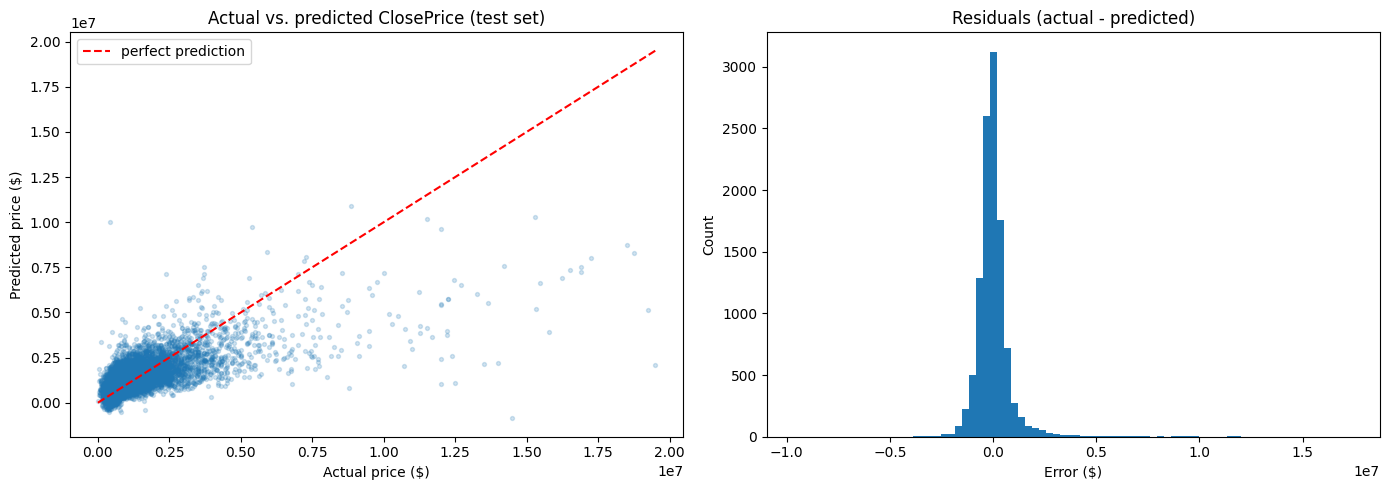

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs predicted
axes[0].scatter(y_test, test_preds, alpha=0.2, s=8)
lims = [0, max(y_test.max(), test_preds.max())]
axes[0].plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
axes[0].set_title("Actual vs. predicted ClosePrice (test set)")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].legend()

# Residuals
residuals = y_test - test_preds
axes[1].hist(residuals, bins=80)
axes[1].set_title("Residuals (actual - predicted)")
axes[1].set_xlabel("Error ($)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


In [26]:
baseline_results = pd.DataFrame([{
    "model": "Linear Regression (baseline)",
    "train_rows": len(train),
    "test_rows": len(test),
    "n_features": len(feature_cols),
    "train_R2": round(train_r2, 4),
    "test_R2": round(test_r2, 4),
    "test_MAE": round(test_mae, 0),
    "test_RMSE": round(test_rmse, 0),
}])

os.makedirs(DATA_DIR, exist_ok=True)
baseline_results.to_csv(os.path.join(DATA_DIR, "baseline_results.csv"), index=False)
baseline_results


,model,train_rows,test_rows,n_features,train_R2,test_R2,test_MAE,test_RMSE
0,Linear Regression (baseline),265372,11178,7,0.492,0.48,515189.0,937893.0


**Findings**

**Baseline Result** The linear regression baseline got a test R^2 of 0.48 (train R^2 of 0.49). This means the model explains a little under half of the variation in ClosePrice for the test month (9/2026). The average error is large in dollar terms: MAE = $515,189 and RMSE = $937,893. These match the X = 24 result from the previous sweep, which is a good sign the pipeline is consistent. The model used 7 features and was trained on 265,372 rows and tested on 11,178 rows.

**Overfitting Check** Train R^2 (0.492) and test R^2 (0.480) are very close, so the model isn't overfitting. It also means the test month behaves a lot like the training months. The model is just limited by being simple, not by memorizing the training data.

**Coefficients** Living Area has the biggest effect, followed by BathroomsTotalInteger. This matches the previous findings where LivingArea has the strongest correlation with ClosePrice. A few coefficients are negative, which looked at first. I don't think the bedroom one means more bedtooms lower the price. LivingArea and bedrooms are highly correlated so once the model already knows the square footage, extra bedrooms mostly just mean smaller rooms. The same overlap probably explains why city_freq and postalcode_freq have opposite signs.

**Plot** In the actual vs. predicted plot, the points follow the red line for typical homes but fall well below it for expensive ones, so the model under-predicts high-priced sales. The residuals are centered near zero but have a long right tail from those big misses, which is why RMSE is almost double MAE. A few predictions also came out negative, which can happen with linear regression because nothing stops it from predicting below zero.